<a href="https://colab.research.google.com/github/aulnr43/final_peoject_tsdw/blob/main/notebooks/02_quality_assessment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
REPO_URL = "https://github.com/aulnr43/final_peoject_tsdw.git"
REPO_DIR = Path("/content/final_peoject_tsdw")

if not REPO_DIR.exists():
  !git clone {REPO_URL} {REPO_DIR}
else:
  !git -C {REPO_DIR} pull

remote: Enumerating objects: 45, done.
remote: Counting objects: 100% (45/45), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 40 (delta 29), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (40/40), 306.41 KiB | 2.95 MiB/s, done.
From https://github.com/aulnr43/final_peoject_tsdw
   3d2e39c..36257f1  main       -> origin/main
Updating 3d2e39c..36257f1
Fast-forward
 notebooks/01_understanding_data.ipynb | 1204 +++++++++++++++++++++++++++------
 notebooks/02_quality_assessment.ipynb | 1042 +++++++++++++++++++++++++---
 reports/data_dictionary.csv           |   33 -
 3 files changed, 1953 insertions(+), 326 deletions(-)
 delete mode 100644 reports/data_dictionary.csv


In [30]:
os.chdir(REPO_DIR)
print("Folder aktif:", os.getcwd())
print("Isi data/raw:", os.listdir("data/raw"))

Folder aktif: /content/final_peoject_tsdw
Isi data/raw: ['hotels.csv', 'H2.csv', 'readme.md', 'hotel_bookings.png', 'H1.csv']


In [31]:
raw_dir = Path("data/raw")
csv_files = {f.name: f for f in raw_dir.glob("*.csv")}
print("CSV terdeteksi:", list(csv_files.keys()))

H1 = pd.read_csv(csv_files["H1.csv"])
H2 = pd.read_csv(csv_files["H2.csv"])
hotels = pd.read_csv(csv_files["hotels.csv"])

print("H1:", H1.shape, "| H2:", H2.shape, "| hotels:", hotels.shape)

CSV terdeteksi: ['hotels.csv', 'H2.csv', 'H1.csv']
H1: (40060, 31) | H2: (79330, 31) | hotels: (119390, 32)


In [32]:
missing_df = pd.DataFrame({
    "kolom": hotels.columns,
    "dtype": hotels.dtypes.astype(str).values,
    "missing_count": hotels.isna().sum().values,
    "missing_pct": (hotels.isna().mean() * 100).round(2).values,
    "non_null_count": hotels.notna().sum().values,
})
missing_df = missing_df[missing_df["missing_count"] > 0].sort_values(
    "missing_count", ascending=False
)
display(missing_df)

print("\nBaris dengan missing 'children':")
display(
    hotels[hotels["children"].isna()][
        ["hotel", "adults", "children", "babies", "market_segment"]
    ]
)

print("\nMissing per jenis hotel:")
display(
    hotels.groupby("hotel")[["company", "agent", "country", "children"]].apply(
        lambda g: g.isna().sum()
    )
)

,kolom,dtype,missing_count,missing_pct,non_null_count
24,company,float64,112593,94.31,6797
23,agent,float64,16340,13.69,103050
13,country,object,488,0.41,118902
10,children,float64,4,0.00,119386



Baris dengan missing 'children':


,hotel,adults,children,babies,market_segment
40600,City Hotel,2,NaN,0,Undefined
40667,City Hotel,2,NaN,0,Direct
40679,City Hotel,3,NaN,0,Undefined
41160,City Hotel,2,NaN,0,Online TA



Missing per jenis hotel:


,company,agent,country,children
hotel,,,,
City Hotel,75641,8131,24,4
Resort Hotel,36952,8209,464,0


In [33]:
exact_dup_count = int(hotels.duplicated().sum())
print(
    f"Duplikat persis (seluruh kolom): {exact_dup_count:,}"
    f" ({exact_dup_count/len(hotels)*100:.2f}%)"
)

key_cols = [
    "hotel",
    "lead_time",
    "arrival_date_year",
    "arrival_date_month",
    "arrival_date_day_of_month",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "meal",
    "country",
    "market_segment",
    "adr",
    "customer_type",
]
partial_dup_count = int(hotels.duplicated(subset=key_cols).sum())
print(
    f"Potensi duplikat (atribut pemesanan inti): {partial_dup_count:,}"
    f" ({partial_dup_count/len(hotels)*100:.2f}%)"
)

display(
    hotels[hotels.duplicated(keep=False)]
    .sort_values(["hotel", "lead_time", "adr"])
    .head(10)
)

Duplikat persis (seluruh kolom): 31,994 (26.80%)
Potensi duplikat (atribut pemesanan inti): 36,078 (30.22%)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
40643,City Hotel,1,0,2015,August,32,4,0,1,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Canceled,2015-08-04
40644,City Hotel,1,0,2015,August,32,4,0,1,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Canceled,2015-08-04
61244,City Hotel,1,0,2016,December,50,6,0,0,0,...,No Deposit,NaN,279.0,0,Transient,0.0,0,0,Canceled,2016-12-06
61245,City Hotel,1,0,2016,December,50,6,0,0,0,...,No Deposit,NaN,279.0,0,Transient,0.0,0,0,Canceled,2016-12-06
61249,City Hotel,1,0,2016,December,50,6,0,0,0,...,No Deposit,NaN,279.0,0,Transient,0.0,0,0,Canceled,2016-12-06
65907,City Hotel,1,0,2017,April,15,10,0,0,0,...,No Deposit,NaN,279.0,0,Transient,0.0,0,0,Canceled,2017-04-10
65908,City Hotel,1,0,2017,April,15,10,0,0,0,...,No Deposit,NaN,279.0,0,Transient,0.0,0,0,Canceled,2017-04-10
65909,City Hotel,1,0,2017,April,15,10,0,0,0,...,No Deposit,NaN,279.0,0,Transient,0.0,0,0,Canceled,2017-04-10
65910,City Hotel,1,0,2017,April,15,10,0,0,0,...,No Deposit,NaN,279.0,0,Transient,0.0,0,0,Canceled,2017-04-10
72967,City Hotel,1,0,2017,August,32,11,0,0,0,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Canceled,2017-08-11


In [34]:
cat_cols = [
    "hotel",
    "meal",
    "market_segment",
    "distribution_channel",
    "deposit_type",
    "customer_type",
    "reservation_status",
]
for col in cat_cols:
  print(f"\n=== {col} ===")
  print(hotels[col].value_counts(dropna=False))

print("\nTipe data kolom tanggal & jumlah tamu:")
print(
    hotels[[
        "arrival_date_year",
        "arrival_date_month",
        "arrival_date_week_number",
        "arrival_date_day_of_month",
        "children",
        "reservation_status_date",
    ]].dtypes
)

zero_guests = (
    hotels["adults"].fillna(0)
    + hotels["children"].fillna(0)
    + hotels["babies"].fillna(0)
) == 0
zero_adults = hotels["adults"] == 0
neg_adr = hotels["adr"] < 0
zero_adr = hotels["adr"] == 0
zero_nights = (
    hotels["stays_in_weekend_nights"] + hotels["stays_in_week_nights"]
) == 0
neg_lead = hotels["lead_time"] < 0
status_mismatch = (
    (hotels["reservation_status"] == "Check-Out") & (hotels["is_canceled"] != 0)
) | (
    (hotels["reservation_status"] == "Canceled") & (hotels["is_canceled"] != 1)
)

print("\n--- Pelanggaran Aturan Domain ---")
print(f"Total tamu = 0                                : {zero_guests.sum():,}")
print(f"Dewasa = 0 (adults == 0)                      : {zero_adults.sum():,}")
print(f"ADR negatif (adr < 0)                         : {neg_adr.sum():,}")
print(f"ADR nol (adr == 0)                            : {zero_adr.sum():,}")
print(f"Total malam menginap = 0                      : {zero_nights.sum():,}")
print(f"Lead time negatif (lead_time < 0)             : {neg_lead.sum():,}")
print(
    f"Inkonsistensi reservation_status & is_canceled: {status_mismatch.sum():,}"
)

if neg_adr.sum() > 0:
  display(
      hotels[neg_adr][[
          "hotel",
          "is_canceled",
          "adr",
          "reservation_status",
          "reservation_status_date",
      ]]
  )


=== hotel ===
hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

=== meal ===
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64

=== market_segment ===
market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64

=== distribution_channel ===
distribution_channel
TA/TO        97870
Direct       14645
Corporate     6677
GDS            193
Undefined        5
Name: count, dtype: int64

=== deposit_type ===
deposit_type
No Deposit    104641
Non Refund     14587
Refundable       162
Name: count, dtype: int64

=== customer_type ===
customer_type
Transient          89613
Transient-Party    25124
Contract            4076
Group                577
Name: count, dtype: int64

=== reservation_status ===
reservation_status
Check-Out    7

,hotel,is_canceled,adr,reservation_status,reservation_status_date
14969,Resort Hotel,0,-6.38,Check-Out,2017-03-15


In [35]:
# Audit Konsistensi Kategori
category_audit = []

for col in cat_cols:
    uniq = pd.Series(hotels[col].dropna().astype(str).unique())
    # kategori unik saja (bukan 119.390 baris), nilai kosong dibuang, diubah jadi teks

    norm = uniq.str.strip().str.lower()
    # versi dinormalkan: spasi dibuang, huruf jadi kecil semua

    category_audit.append({
        "variable": col,                                    # nama kolom yang diperiksa
        "unique_categories": len(uniq),                     # jumlah kategori berbeda
        "whitespace_count": int(
            uniq.ne(uniq.str.strip()).sum()                 # kategori yang punya spasi di awal/akhir
        ),
        "case_variation_count": int(len(uniq) - norm.nunique())
        # kategori awal dikurangi kategori setelah dinormalkan, 0 = tidak ada variasi penulisan
    })

category_audit_df = pd.DataFrame(category_audit)
display(category_audit_df)

,variable,unique_categories,whitespace_count,case_variation_count
0,hotel,2,0,0
1,meal,5,0,0
2,market_segment,8,0,0
3,distribution_channel,5,0,0
4,deposit_type,3,0,0
5,customer_type,4,0,0
6,reservation_status,3,0,0


##### **Keterangan Hasil Audit Kategori:**
- `unique_categories`: jumlah variasi kategorik yang muncul di tiap kolom, misalnya hotel ada 2 variasi dan meal ada 5 variasi.
- `whitespace_count`: jumlah kategori yang memiliki spasi tambahan di awal atau akhir teks (seperti "BB "), yang dapat membuat satu kategori terbaca jadi dua nilai berbeda.
- `case_variation_count`: selisih jumlah kategori sebelum dan sesudah dirapikan ke huruf kecil, untuk mendeteksi label yang sama namun beda kapitalisasi (misalnya "BB" vs "bb"). Nilai 0 berarti tidak ada perbedaan penulisan akibat huruf besar/kecil.

Ketiga kolom ini diperiksa agar penulisan kategori tidak terpecah akibat spasi berlebih atau perbedaan huruf kapital sebelum masuk ke pemeriksaan isi kategorinya. Pada tabel ini, seluruh kolom menunjukkan whitespace_count = 0 dan case_variation_count = 0, sehingga penulisan formatnya sudah seragam. Tahap berikutnya perlu memeriksa apakah ada kategori yang maknanya masih kurang jelas (seperti "Undefined").

In [36]:
# Pemeriksaan Kategori "Undefined"
for col in cat_cols:
    teks = hotels[col].astype("string")

    cocok = teks.str.strip().str.lower().eq("undefined")
    # buang spasi, kecilkan huruf, lalu cek apakah isinya "undefined"
    # hasilnya True/False per baris, jadi "Undefined" dan "undefined " ikut terhitung

    n = int(cocok.sum())
    print(f"{col:22s}: {n:>5,} baris Undefined ({n / len(hotels) * 100:.3f}%)")
    # :22s = rata kiri lebar 22 karakter, :>5, = angka rata kanan dengan pemisah ribuan

hotel                 :     0 baris Undefined (0.000%)
meal                  : 1,169 baris Undefined (0.979%)
market_segment        :     2 baris Undefined (0.002%)
distribution_channel  :     5 baris Undefined (0.004%)
deposit_type          :     0 baris Undefined (0.000%)
customer_type         :     0 baris Undefined (0.000%)
reservation_status    :     0 baris Undefined (0.000%)


**Keterangan Pemeriksaan Kategori "Undefined":**
- Label "Undefined" bukan sel kosong (NaN), melainkan nilai teks yang menandakan kategorinya belum tercatat secara jelas. Meski format penulisannya sudah seragam pada pengecekan sebelumnya, label ini tetap terbaca sebagai kategori tersendiri sehingga perlu diperiksa agar tidak keliru saat dianalisis dan dapat ditentukan penanganannya pada tahap cleaning.
- Nilai "undefined" paling banyak ditemukan pada kolom `meal` (1.169 baris / 0,979%), diikuti `distribution_channel` (5 baris / 0,004%) serta `market_segment` (2 baris / 0,002%), sedangkan pada `hotel`, `deposit_type`, `customer_type`, dan `reservation_status` tidak ditemukan (0 baris).
- Hasil ini menunjukkan bahwa ketidakjelasan kategori paling banyak terjadi pada jenis paket makan (`meal`), sementara pada kolom lainnya jumlahnya sangat sedikit atau tidak ada sama sekali.

In [37]:
# Pemeriksaan nilai biner
binary_invalid = (
    hotels["is_canceled"].notna()
    & ~hotels["is_canceled"].isin([0, 1])
)

repeat_invalid = (
    hotels["is_repeated_guest"].notna()
    & ~hotels["is_repeated_guest"].isin([0, 1])
)

# Pemeriksaan nilai kalender
week_invalid = (
    hotels["arrival_date_week_number"].notna()
    & ~hotels["arrival_date_week_number"].between(1, 53)
)

day_invalid = (
    hotels["arrival_date_day_of_month"].notna()
    & ~hotels["arrival_date_day_of_month"].between(1, 31)
)

# Ringkasan hasil
domain_summary = pd.DataFrame({
    "variable": [
        "is_canceled",
        "is_repeated_guest",
        "arrival_date_week_number",
        "arrival_date_day_of_month"
    ],
    "invalid_count": [
        binary_invalid.sum(),
        repeat_invalid.sum(),
        week_invalid.sum(),
        day_invalid.sum()
    ]
})

display(domain_summary)

,variable,invalid_count
0,is_canceled,0
1,is_repeated_guest,0
2,arrival_date_week_number,0
3,arrival_date_day_of_month,0


In [47]:
domain_results = [
    {
        "variable": "is_canceled",
        "rule": "0 or 1",
        "invalid_count": int(binary_invalid.sum())
    },
    {
        "variable": "is_repeated_guest",
        "rule": "0 or 1",
        "invalid_count": int(repeat_invalid.sum())
    },
    {
        "variable": "arrival_date_week_number",
        "rule": "1 to 53",
        "invalid_count": int(week_invalid.sum())
    },
    {
        "variable": "arrival_date_day_of_month",
        "rule": "1 to 31",
        "invalid_count": int(day_invalid.sum())
    }
]

domain_audit_df = pd.DataFrame(domain_results)

display(domain_audit_df)

,variable,rule,invalid_count
0,is_canceled,0 or 1,0
1,is_repeated_guest,0 or 1,0
2,arrival_date_week_number,1 to 53,0
3,arrival_date_day_of_month,1 to 31,0


#### **Keterangan Pemeriksaan Nilai Biner dan Kalender:**
- Pemeriksaan ini perlu dilakukan untuk memastikan nilai pada variabel biner (0 atau 1) serta penanggalan (`arrival_date_week_number` pada rentang 1-53 dan `arrival_date_day_of_month` pada rentang 1-31) masih berada di batas yang wajar sebelum data dipakai lebih jauh, agar tidak ada angka di luar aturan domain yang lolos tanpa terdeteksi.
- Dari tabel ringkasan, seluruh variabel menunjukkan `invalid_count = 0`, yang berarti tidak ada nilai tidak kosong yang melanggar aturan biner maupun kalender pada keempat kolom tersebut.
- Hasil ini memberikan kepastian bahwa keempat kolom tersebut sudah cukup aman dari sisi rentang nilai, sehingga tidak memerlukan perbaikan nilai anomali pada tahap cleaning berikutnya.

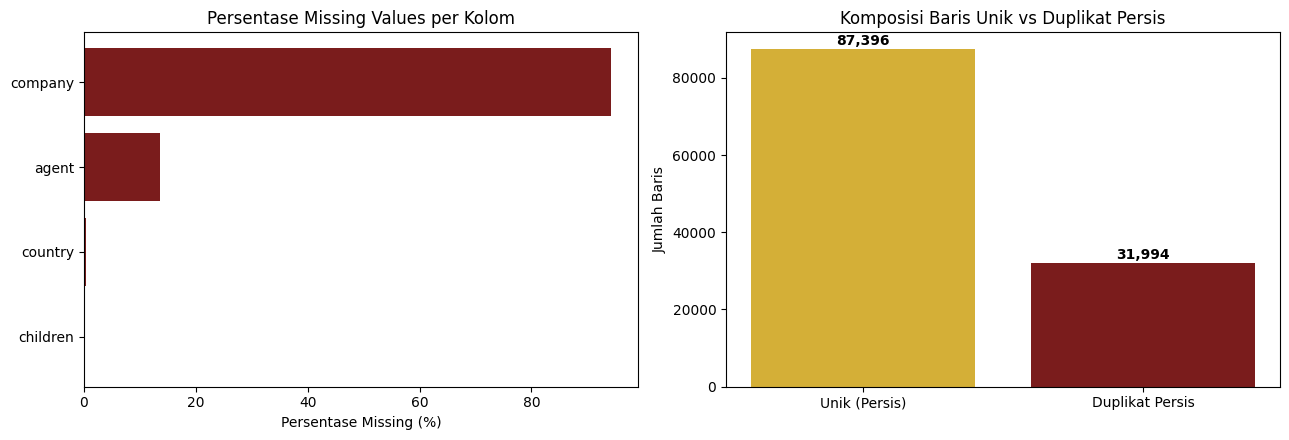

,indikator,nilai_persen,rumus,keterangan
0,Completeness,96.61,1 - (sel kosong / total sel),"Terdapat 129,425 sel kosong dari 3,820,480 sel..."
1,Uniqueness,73.20,1 - (duplikat persis / total baris),"Terdapat 31,994 baris duplikat persis dari 119..."
2,Validity,99.31,1 - (baris melanggar aturan domain / total baris),Terdapat 826 baris tidak valid (gabungan tamu=...
3,Consistency,100.00,1 - (baris inkonsisten status vs is_canceled /...,Terdapat 0 baris tidak konsisten antara reserv...


Tersimpan di: reports/data_quality_indicators.csv


In [38]:
# 1. Grafik Missing Values & Duplikat (Task B.2)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

top_miss = missing_df.sort_values("missing_pct", ascending=True)
axes[0].barh(top_miss["kolom"], top_miss["missing_pct"], color="#7A1C1C")
axes[0].set_title("Persentase Missing Values per Kolom")
axes[0].set_xlabel("Persentase Missing (%)")

dup_counts = [len(hotels) - exact_dup_count, exact_dup_count]
axes[1].bar(
    ["Unik (Persis)", "Duplikat Persis"],
    dup_counts,
    color=["#D4AF37", "#7A1C1C"],
)
axes[1].set_title("Komposisi Baris Unik vs Duplikat Persis")
axes[1].set_ylabel("Jumlah Baris")
for i, v in enumerate(dup_counts):
  axes[1].text(i, v + 1000, f"{v:,}", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig(figures_dir / "missing_and_duplicates.png", dpi=150)
plt.show()

# 2. Ringkasan 4 Indikator Kualitas Data Lengkap + Keterangan (Task B.3)
quality_4_indikator = pd.DataFrame({
    "indikator": ["Completeness", "Uniqueness", "Validity", "Consistency"],
    "nilai_persen": [
        round(completeness_pct, 2),
        round(uniqueness_pct, 2),
        round(validity_pct, 2),
        round(consistency_pct, 2),
    ],
    "rumus": [
        "1 - (sel kosong / total sel)",
        "1 - (duplikat persis / total baris)",
        "1 - (baris melanggar aturan domain / total baris)",
        "1 - (baris inkonsisten status vs is_canceled / total baris)",
    ],
    "keterangan": [
        (
            f"Terdapat {missing_cells:,} sel kosong dari {total_cells:,} sel"
            " (tertinggi di company 94,31% dan agent 13,69%)."
        ),
        (
            f"Terdapat {exact_dup_count:,} baris duplikat persis dari"
            f" {len(hotels):,} baris (perlu dicek apakah duplikat input atau"
            " reservasi berulang)."
        ),
        (
            f"Terdapat {int(invalid_mask.sum()):,} baris tidak valid"
            " (gabungan tamu=0, adr<0, atau total malam=0)."
        ),
        (
            f"Terdapat {int(status_mismatch.sum()):,} baris tidak konsisten"
            " antara reservation_status dan is_canceled."
        ),
    ],
})
display(quality_4_indikator)

# Simpan juga ringkasan indikator ke CSV terpisah agar rapi dan mudah dibaca
indikator_path = reports_dir / "data_quality_indicators.csv"
quality_4_indikator.to_csv(indikator_path, index=False)
print("Tersimpan di:", indikator_path)

In [39]:
num_cols = [
    "lead_time",
    "adr",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "booking_changes",
    "previous_cancellations",
    "days_in_waiting_list",
]

outlier_rows = []
for col in num_cols:
  s = hotels[col].dropna()
  q1 = s.quantile(0.25)
  q3 = s.quantile(0.75)
  iqr = q3 - q1
  lower = q1 - 1.5 * iqr
  upper = q3 + 1.5 * iqr
  mask = (s < lower) | (s > upper)
  outlier_rows.append({
      "variabel": col,
      "Q1": round(q1, 2),
      "Q3": round(q3, 2),
      "IQR": round(iqr, 2),
      "batas_bawah": round(lower, 2),
      "batas_atas": round(upper, 2),
      "jumlah_outlier": int(mask.sum()),
      "persen_outlier": round(float(mask.mean() * 100), 2),
      "min_aktual": s.min(),
      "max_aktual": s.max(),
  })

df_outliers = pd.DataFrame(outlier_rows)
display(df_outliers)

print("\n5 baris dengan ADR tertinggi:")
display(
    hotels.sort_values("adr", ascending=False)[
        ["hotel", "is_canceled", "adr", "adults", "children", "market_segment"]
    ].head(5)
)

,variabel,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_outlier,persen_outlier,min_aktual,max_aktual
0,lead_time,18.00,160.0,142.00,-195.00,373.00,3005,2.52,0.00,737.0
1,adr,69.29,126.0,56.71,-15.77,211.06,3793,3.18,-6.38,5400.0
2,stays_in_weekend_nights,0.00,2.0,2.00,-3.00,5.00,265,0.22,0.00,19.0
3,stays_in_week_nights,1.00,3.0,2.00,-2.00,6.00,3354,2.81,0.00,50.0
4,booking_changes,0.00,0.0,0.00,0.00,0.00,18076,15.14,0.00,21.0
5,previous_cancellations,0.00,0.0,0.00,0.00,0.00,6484,5.43,0.00,26.0
6,days_in_waiting_list,0.00,0.0,0.00,0.00,0.00,3698,3.10,0.00,391.0



5 baris dengan ADR tertinggi:


,hotel,is_canceled,adr,adults,children,market_segment
48515,City Hotel,1,5400.0,2,0.0,Offline TA/TO
111403,City Hotel,0,510.0,1,0.0,Offline TA/TO
15083,Resort Hotel,0,508.0,2,0.0,Corporate
103912,City Hotel,0,451.5,2,2.0,Direct
13142,Resort Hotel,1,450.0,2,0.0,Online TA


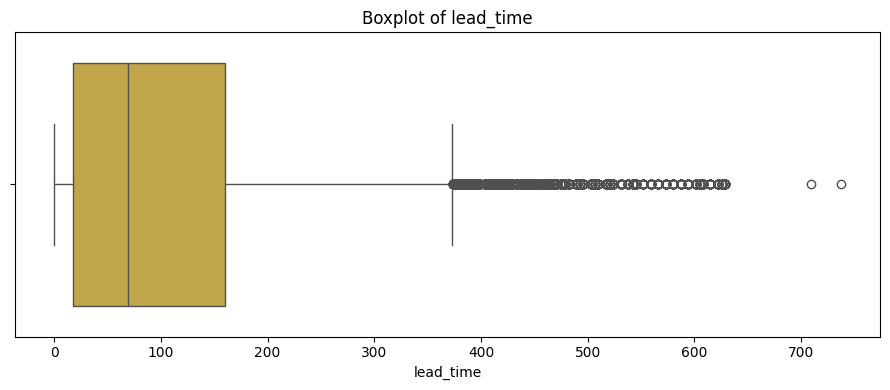

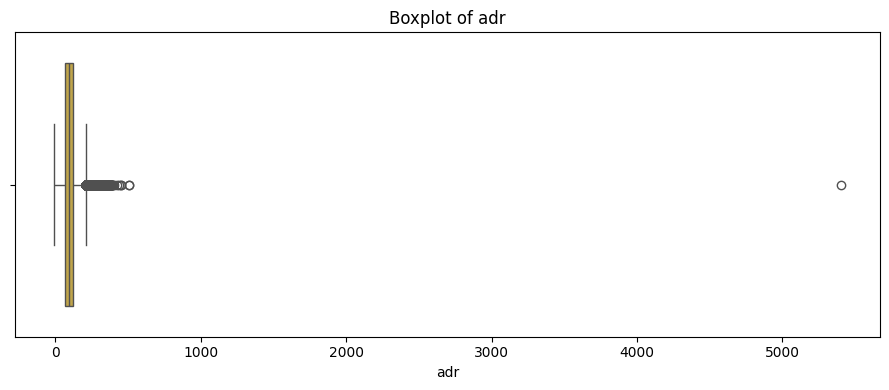

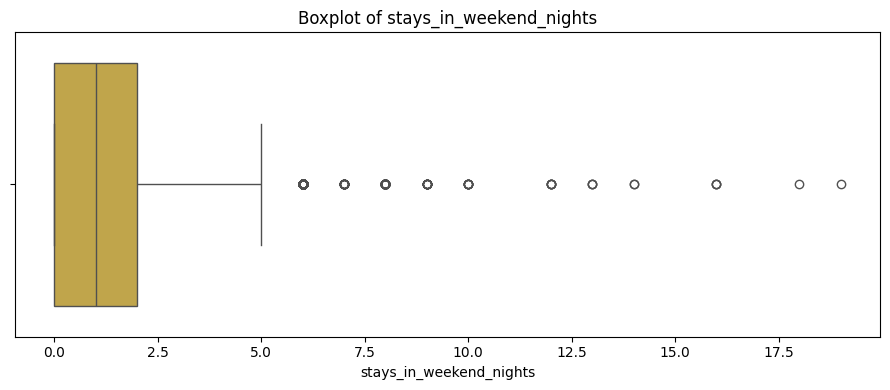

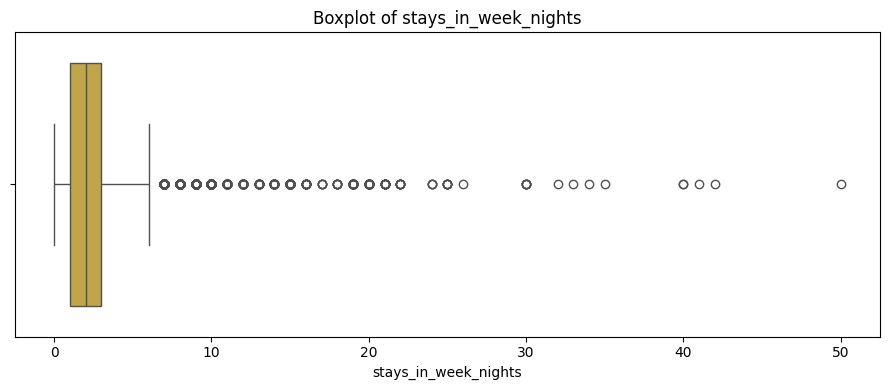

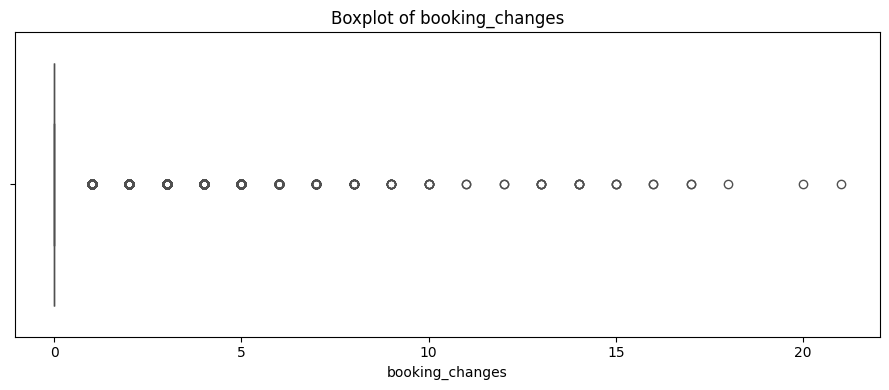

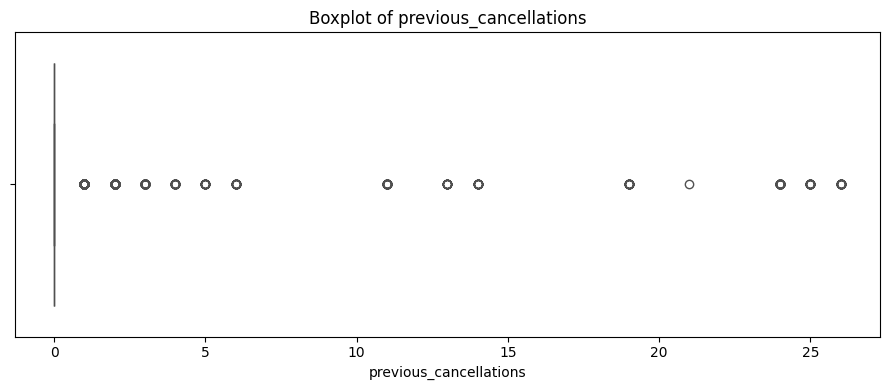

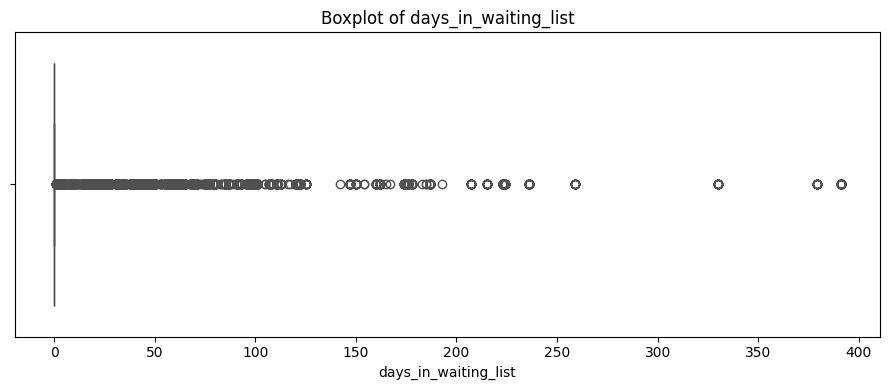

In [40]:
# Boxplot untuk setiap variabel outlier
for col in num_cols:
    plt.figure(figsize=(9, 4))

    sns.boxplot(
        x=hotels[col],
        color="#D4AF37"
    )

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()

    plt.savefig(
        figures_dir / f"boxplot_{col}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

#### **Catatan dari Boxplot Outlier:**
- Boxplot ini digunakan sebagai visualisasi pendukung untuk melengkapi hitungan IQR sebelumnya, sekaligus menyimpan gambarnya sebagai bahan dokumentasi.
- Untuk `stays_in_weekend_nights` dan `stays_in_week_nights`, kebanyakan pemesanan berada di jumlah malam yang rendah, lalu ada beberapa titik yang cukup jauh di kanan (hingga sekitar 20 dan 50 malam). Hal ini bisa saja terjadi karena memang ada tamu dengan masa menginap panjang, jadi perlu dicek konteksnya dulu sebelum disimpulkan keliru.
- Pada `adr`, mayoritas tarif mengumpul di rentang yang jauh lebih kecil, namun ada satu titik ekstrem di atas 5.000 yang membuat skala sumbu melebar dan patut diperiksa apakah termasuk kesalahan input atau kasus tarif khusus.
- Sementara pada `booking_changes`, `previous_cancellations`, dan `days_in_waiting_list`, sebagian besar datanya ada di angka 0. Akibatnya kotaknya terlihat sangat tipis dan nilai-nilai di sebelah kanannya muncul sebagai *outlier* karena jarang terjadi dibanding mayoritas data.

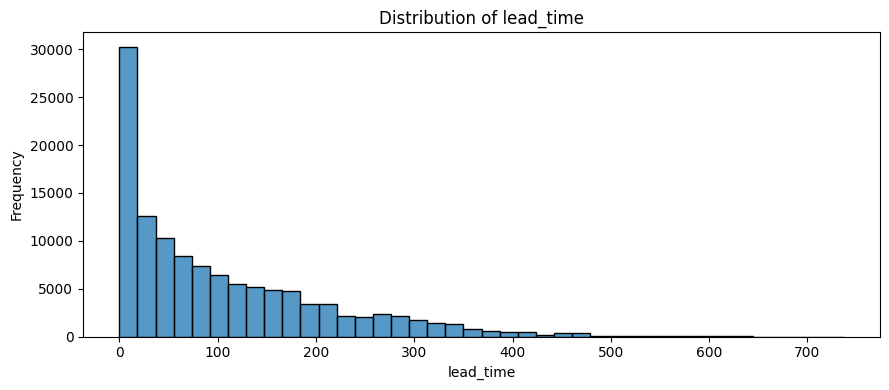

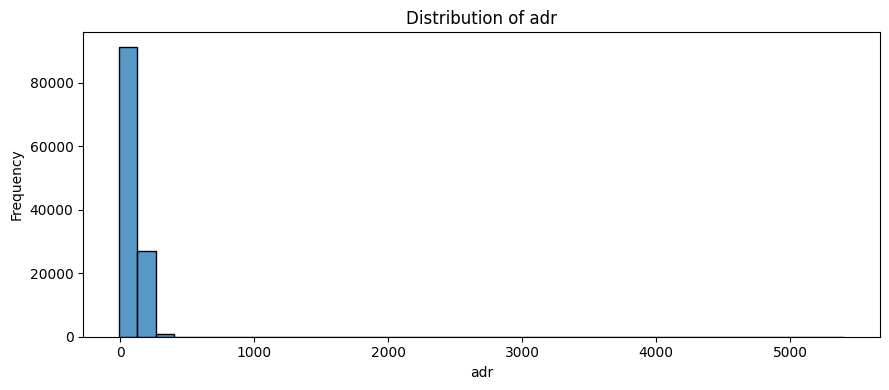

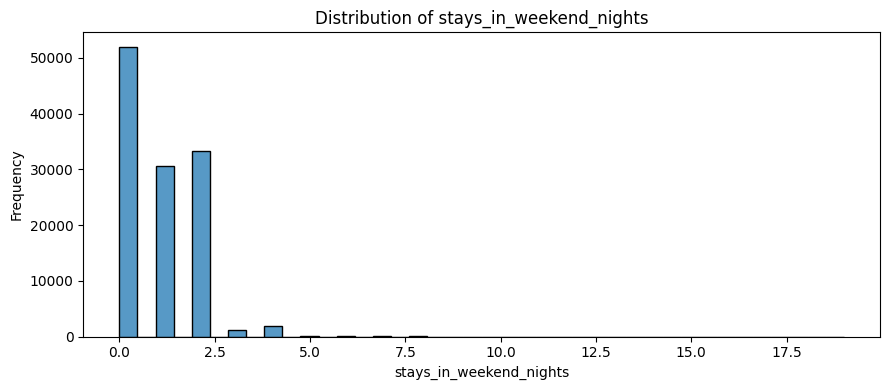

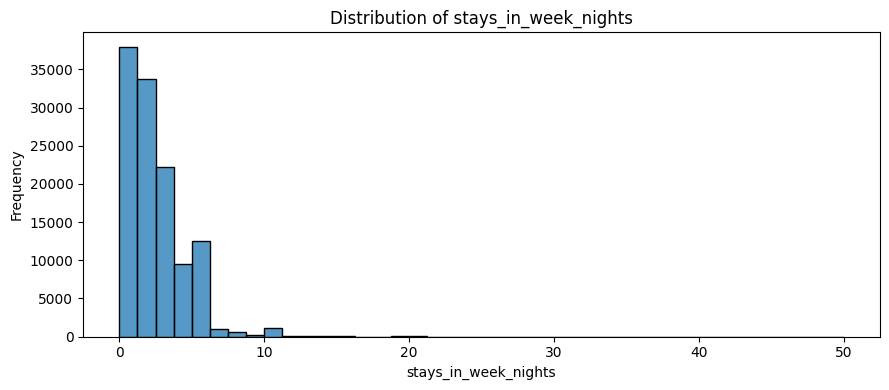

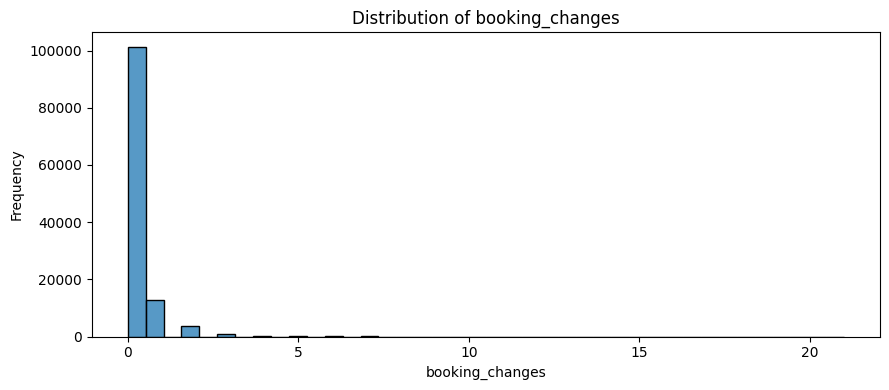

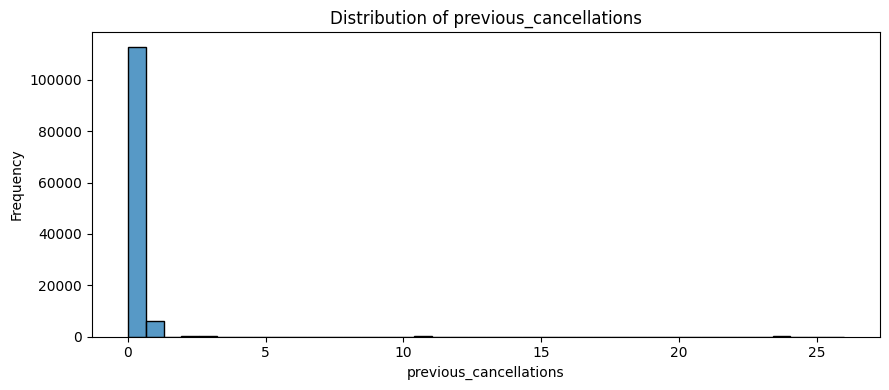

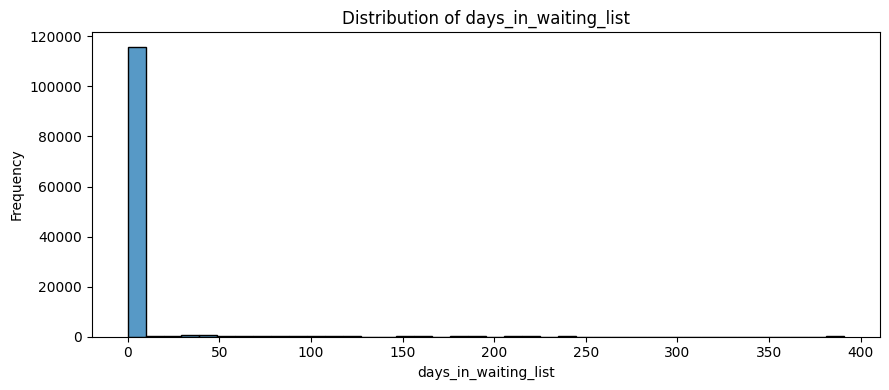

In [41]:
# Histogram untuk setiap variabel outlier
for col in num_cols:
    plt.figure(figsize=(9, 4))

    sns.histplot(
        data=hotels,
        x=col,
        bins=40
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()

    plt.savefig(
        figures_dir / f"distribution_{col}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

#### **Insight Histogram Variabel Outlier**

Seluruh variabel di `num_cols` cenderung miring ke kanan (*right-skewed*) dengan ekor panjang ke nilai besar.

- `lead_time`: Terbanyak di dekat 0 hari (>30.000 data), lalu melandai hingga sekitar 450-500 hari dengan ekor sampai >700 hari.
- `adr`: Sebagian besar menumpuk di dekat 0 (jauh di bawah 1000), sedangkan rentang sumbu X melebar hingga di atas 5000 dengan frekuensi sangat kecil (perlu cek juga nilai <= 0).
- `stays_in_weekend_nights`: Paling banyak di 0, 1, dan 2 malam (tertinggi di 0, lalu 2 dan 1), dengan ekor kecil memanjang hingga mendekati 20 malam.
- `stays_in_week_nights`: Tertinggi di dekat 0 malam, diikuti 1 dan 2 malam, lalu melandai hingga 50 malam.
- `booking_changes`: Sangat didominasi 0 (>100.000 data), sedikit di 1-3, dan menyisakan ekor jarang sampai >20.
- `previous_cancellations`: Hampir semuanya 0 (>100.000 data), sedikit di 1, serta ada klaster kecil di sekitar 10-13 dan 24-26.
- `days_in_waiting_list`: Sangat terpusat di 0 (>115.000 data), sisanya tersebar tipis hingga mendekati 400 hari.

Nilai ekstrem di ekor kanan sebaiknya dicek dulu antara kasus bisnis wajar dan anomali sebelum diputuskan pada tahap *cleaning*.

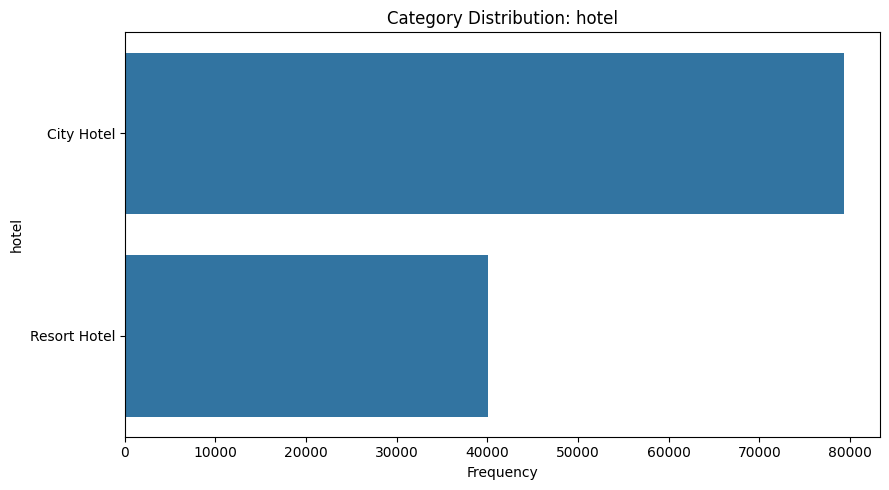

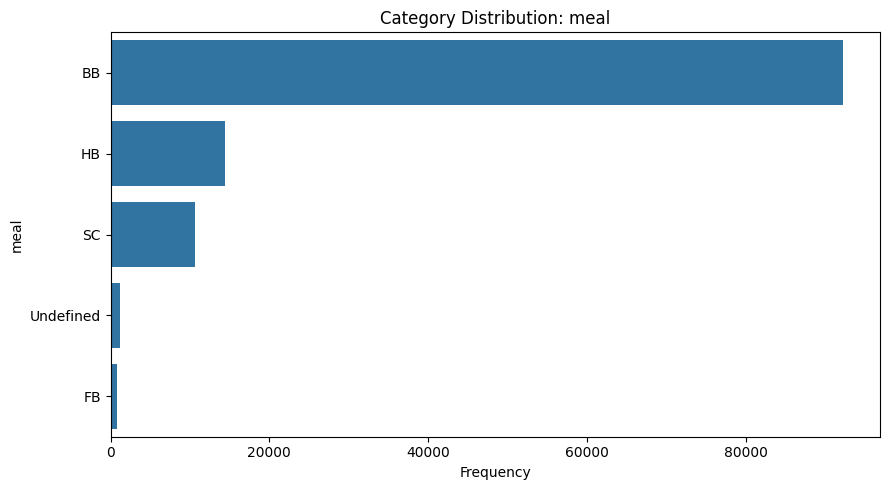

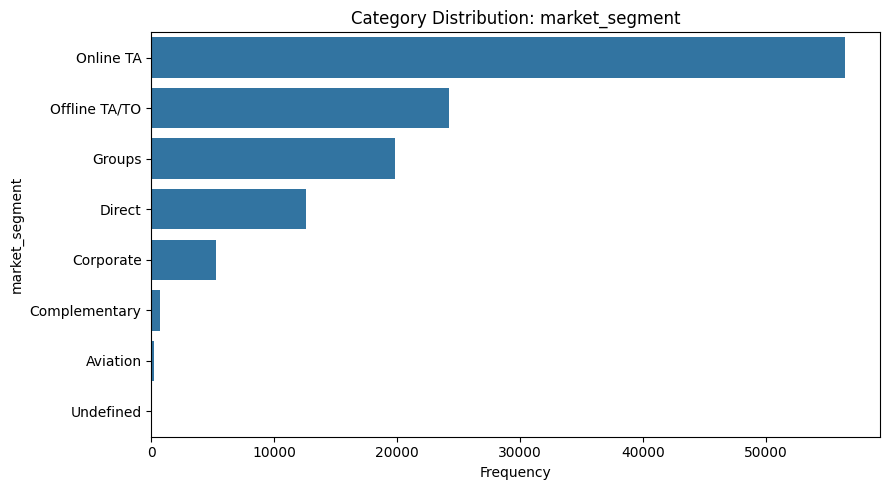

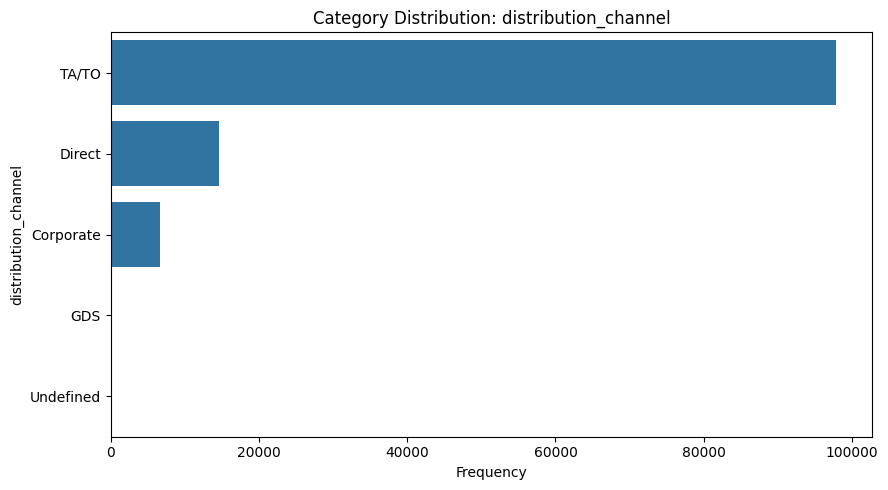

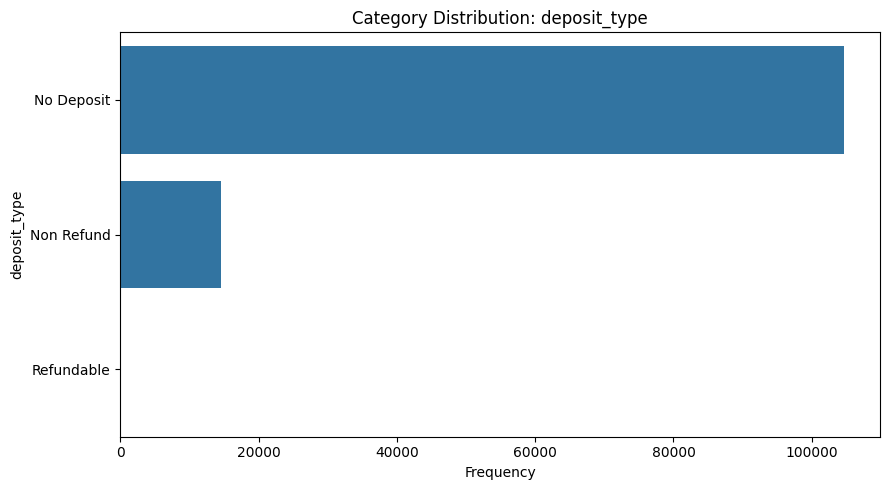

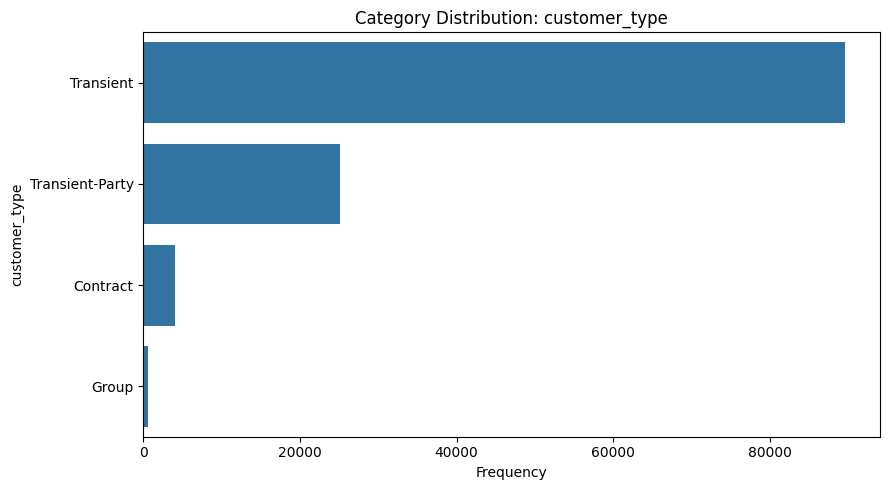

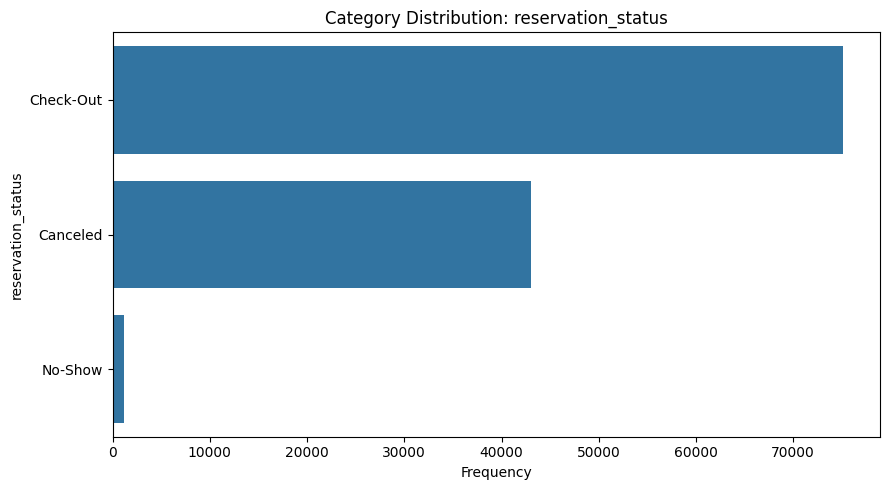

In [42]:
# Visualisasi distribusi kategori
for col in cat_cols:
    plt.figure(figsize=(9, 5))

    counts = hotels[col].value_counts(
        dropna=False
    )

    sns.barplot(
        x=counts.values,
        y=counts.index.astype(str)
    )

    plt.title(f"Category Distribution: {col}")
    plt.xlabel("Frequency")
    plt.ylabel(col)
    plt.tight_layout()

    plt.savefig(
        figures_dir / f"category_{col}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

#### **Insight Distribusi Variabel Kategorik**

Sebagian besar variabel kategorik didominasi oleh satu atau dua kategori utama, dengan beberapa kategori berfrekuensi jauh lebih kecil.

- `hotel`: Didominasi City Hotel (mendekati 80.000), diikuti Resort Hotel (sekitar 40.000).
- `meal`: Paling banyak BB (>90.000), jauh di atas HB dan SC (masing-masing di kisaran 10.000–15.000), sedangkan Undefined dan FB sangat sedikit.
- `market_segment`: Tertinggi pada Online TA (>55.000), diikuti Offline TA/TO (sekitar 24.000–25.000), Groups (sekitar 20.000), Direct (>10.000), Corporate (lebih dari 5.000), serta Complementary, Aviation, dan Undefined yang sangat kecil.
- `distribution_channel`: Sangat didominasi TA/TO (mendekati 100.000), diikuti Direct (sekitar 15.000) dan Corporate (di bawah 10.000), sementara GDS dan Undefined nyaris tidak terlihat.
- `deposit_type`: Mayoritas besar berada pada No Deposit (>100.000), diikuti Non Refund (sekitar 15.000), sedangkan Refundable sangat kecil.
- `customer_type`: Didominasi Transient (sekitar 90.000), diikuti Transient-Party (sekitar 25.000), lalu Contract dan Group yang jauh lebih sedikit.
- `reservation_status`: Terbanyak pada Check-Out (sekitar 75.000), diikuti Canceled (lebih dari 40.000), dan No-Show yang sangat sedikit.

,indikator,nilai_persen,catatan
0,Completeness,96.61,"129,425 sel kosong dari 3,820,480 sel"
1,Uniqueness,73.20,"31,994 duplikat persis dari 119,390 baris"
2,Validity,99.31,826 baris melanggar aturan tamu/malam/ADR > 0
3,Consistency,100.00,0 baris inkonsisten status vs is_canceled


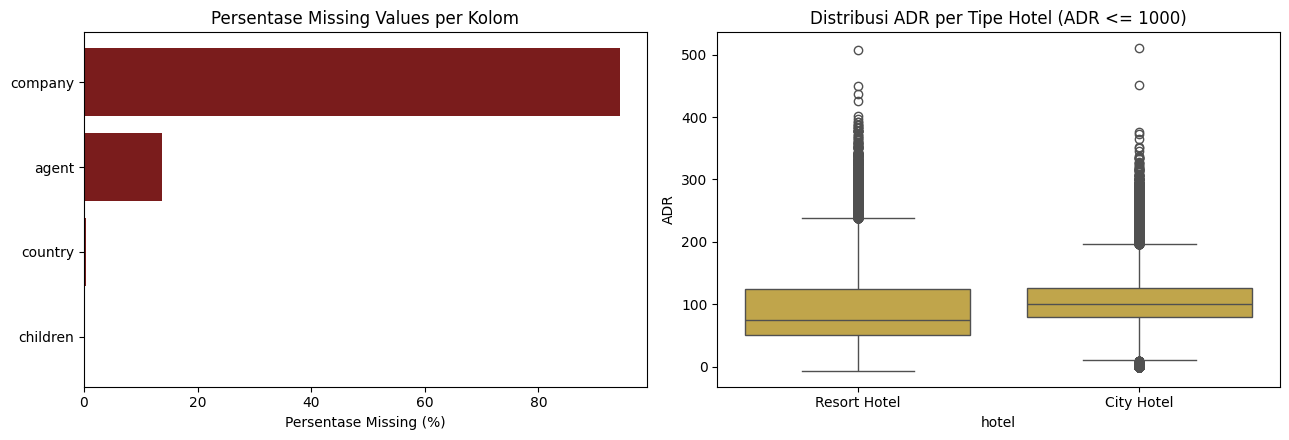

Tersimpan di: reports/quality_issue_log.csv


,issue_id,category,variable,evidence,error_vs_valid,proposed_treatment,final_decision
0,DQ-01,Missing Values,company,"112,593 baris kosong (94.31%)",Kosong karena mayoritas bukan reservasi korporasi,Bandingkan drop kolom vs label 'No Company' di...,Evaluasi di Task C1
1,DQ-02,Missing Values,agent,"16,340 baris kosong (13.69%)",Kosong saat pemesanan tidak melalui agen perja...,Imputasi kategori 'No Agent' atau indikator sa...,Evaluasi di Task C1
2,DQ-03,Missing Values,"country, children",country kosong 488 baris; children kosong 4 baris,Data hilang sebagian kecil (<= 0.41%),Imputasi modus/Unknown untuk country; 0/median...,Evaluasi di Task C1
3,DQ-04,Duplicates,all_columns,"31,994 baris duplikat persis (26.80%)",Perlu dibedakan antara duplikat input dan rese...,Uji penghapusan duplikat & analisis sensitivit...,Evaluasi di Task C2 & C5
4,DQ-05,Invalid Values,adr,"1 baris adr < 0 (min=-6.38) dan 1,959 baris ad...",adr < 0 tidak valid; adr == 0 perlu dicek (pro...,Tangani adr < 0 dan analisis terpisah adr == 0...,Evaluasi di Task C2
5,DQ-06,Invalid / Consistency,"adults, children, babies, stays_*",180 baris tamu = 0; 715 baris malam menginap = 0,Tidak wajar untuk reservasi menginap aktif/pen...,Terapkan aturan validitas di Task C2 & Task D,Evaluasi di Task C2 & D
6,DQ-07,Data Types & Categories,"reservation_status_date, meal, market_segment",reservation_status_date bertipe object; ada la...,Perlu konversi tipe tanggal & standarisasi kat...,Konversi ke datetime dan seragamkan label di T...,Evaluasi di Task C2/C3
7,DQ-08,Outliers,"lead_time, adr, stays_*","Outlier IQR terdeteksi (adr max=5400.0, lead_t...","Sebagian valid secara bisnis, sebagian ekstrem...",Gunakan transformasi/winsorizing & cek sensiti...,Evaluasi di Task C3/C5


In [43]:
figures_dir = Path("figures")
figures_dir.mkdir(parents=True, exist_ok=True)
reports_dir = Path("reports")
reports_dir.mkdir(parents=True, exist_ok=True)

total_cells = hotels.size
missing_cells = int(hotels.isna().sum().sum())
invalid_mask = zero_guests | neg_adr | zero_nights

completeness_pct = (1 - missing_cells / total_cells) * 100
uniqueness_pct = (1 - exact_dup_count / len(hotels)) * 100
validity_pct = (1 - int(invalid_mask.sum()) / len(hotels)) * 100
consistency_pct = (1 - int(status_mismatch.sum()) / len(hotels)) * 100

quality_summary = pd.DataFrame({
    "indikator": ["Completeness", "Uniqueness", "Validity", "Consistency"],
    "nilai_persen": [
        round(completeness_pct, 2),
        round(uniqueness_pct, 2),
        round(validity_pct, 2),
        round(consistency_pct, 2),
    ],
    "catatan": [
        f"{missing_cells:,} sel kosong dari {total_cells:,} sel",
        f"{exact_dup_count:,} duplikat persis dari {len(hotels):,} baris",
        f"{int(invalid_mask.sum()):,} baris melanggar aturan tamu/malam/ADR > 0",
        f"{int(status_mismatch.sum()):,} baris inkonsisten status vs is_canceled",
    ],
})
display(quality_summary)

# Visualisasi missingness & distribusi ADR
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
top_miss = missing_df.sort_values("missing_pct", ascending=True)
axes[0].barh(top_miss["kolom"], top_miss["missing_pct"], color="#7A1C1C")
axes[0].set_title("Persentase Missing Values per Kolom")
axes[0].set_xlabel("Persentase Missing (%)")

adr_plot = hotels[hotels["adr"].between(-20, 1000)]
sns.boxplot(data=adr_plot, x="hotel", y="adr", ax=axes[1], color="#D4AF37")
axes[1].set_title("Distribusi ADR per Tipe Hotel (ADR <= 1000)")
axes[1].set_ylabel("ADR")

plt.tight_layout()
fig_path = figures_dir / "quality_assessment_overview.png"
plt.savefig(fig_path, dpi=150)
plt.show()

# Simpan reports/quality_issue_log.csv
issue_log = [
    {
        "issue_id": "DQ-01",
        "category": "Missing Values",
        "variable": "company",
        "evidence": (
            f"{hotels['company'].isna().sum():,} baris kosong"
            f" ({hotels['company'].isna().mean()*100:.2f}%)"
        ),
        "error_vs_valid": "Kosong karena mayoritas bukan reservasi korporasi",
        "proposed_treatment": (
            "Bandingkan drop kolom vs label 'No Company' di Task C1"
        ),
        "final_decision": "Evaluasi di Task C1",
    },
    {
        "issue_id": "DQ-02",
        "category": "Missing Values",
        "variable": "agent",
        "evidence": (
            f"{hotels['agent'].isna().sum():,} baris kosong"
            f" ({hotels['agent'].isna().mean()*100:.2f}%)"
        ),
        "error_vs_valid": "Kosong saat pemesanan tidak melalui agen perjalanan",
        "proposed_treatment": (
            "Imputasi kategori 'No Agent' atau indikator saluran"
        ),
        "final_decision": "Evaluasi di Task C1",
    },
    {
        "issue_id": "DQ-03",
        "category": "Missing Values",
        "variable": "country, children",
        "evidence": (
            f"country kosong {hotels['country'].isna().sum()} baris; children"
            f" kosong {hotels['children'].isna().sum()} baris"
        ),
        "error_vs_valid": "Data hilang sebagian kecil (<= 0.41%)",
        "proposed_treatment": (
            "Imputasi modus/Unknown untuk country; 0/median untuk children"
        ),
        "final_decision": "Evaluasi di Task C1",
    },
    {
        "issue_id": "DQ-04",
        "category": "Duplicates",
        "variable": "all_columns",
        "evidence": (
            f"{exact_dup_count:,} baris duplikat persis"
            f" ({exact_dup_count/len(hotels)*100:.2f}%)"
        ),
        "error_vs_valid": (
            "Perlu dibedakan antara duplikat input dan reservasi berulang sah"
        ),
        "proposed_treatment": (
            "Uji penghapusan duplikat & analisis sensitivitas di Task C2/C5"
        ),
        "final_decision": "Evaluasi di Task C2 & C5",
    },
    {
        "issue_id": "DQ-05",
        "category": "Invalid Values",
        "variable": "adr",
        "evidence": (
            f"{neg_adr.sum()} baris adr < 0 (min={hotels['adr'].min()}) dan"
            f" {zero_adr.sum():,} baris adr == 0"
        ),
        "error_vs_valid": (
            "adr < 0 tidak valid; adr == 0 perlu dicek (promosi/komplementer)"
        ),
        "proposed_treatment": (
            "Tangani adr < 0 dan analisis terpisah adr == 0 di Task C2"
        ),
        "final_decision": "Evaluasi di Task C2",
    },
    {
        "issue_id": "DQ-06",
        "category": "Invalid / Consistency",
        "variable": "adults, children, babies, stays_*",
        "evidence": (
            f"{zero_guests.sum()} baris tamu = 0; {zero_nights.sum()} baris"
            " malam menginap = 0"
        ),
        "error_vs_valid": "Tidak wajar untuk reservasi menginap aktif/pendapatan",
        "proposed_treatment": "Terapkan aturan validitas di Task C2 & Task D",
        "final_decision": "Evaluasi di Task C2 & D",
    },
    {
        "issue_id": "DQ-07",
        "category": "Data Types & Categories",
        "variable": "reservation_status_date, meal, market_segment",
        "evidence": (
            "reservation_status_date bertipe object; ada label 'Undefined'"
            " pada beberapa kolom kategori"
        ),
        "error_vs_valid": "Perlu konversi tipe tanggal & standarisasi kategori",
        "proposed_treatment": (
            "Konversi ke datetime dan seragamkan label di Task C2/C3"
        ),
        "final_decision": "Evaluasi di Task C2/C3",
    },
    {
        "issue_id": "DQ-08",
        "category": "Outliers",
        "variable": "lead_time, adr, stays_*",
        "evidence": (
            f"Outlier IQR terdeteksi (adr max={hotels['adr'].max()},"
            f" lead_time max={hotels['lead_time'].max()})"
        ),
        "error_vs_valid": (
            "Sebagian valid secara bisnis, sebagian ekstrem perlu dicek"
        ),
        "proposed_treatment": (
            "Gunakan transformasi/winsorizing & cek sensitivitas di Task C3/C5"
        ),
        "final_decision": "Evaluasi di Task C3/C5",
    },
]

df_issue_log = pd.DataFrame(issue_log)
log_path = reports_dir / "quality_issue_log.csv"
df_issue_log.to_csv(log_path, index=False)
print("Tersimpan di:", log_path)
display(df_issue_log)